# M7.5 · 做市与高频

> 做市商同时挂买卖双边报价赚取价差，核心是管理库存与逆向选择风险；
> 高频策略依赖低延迟与队列位置，靠大量小盈利累积。

## 一、机制

1. **双边报价**：中间价两侧挂单，价差覆盖成本；
2. **库存管理**：按库存偏移报价，避免单边累积；
3. **逆向选择**：知情交易者成交后价格继续走，做市商承担价差损失。

## 二、报价与成本

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
from deriv_lab import market_making as mm
bid, ask = mm.make_quote(100, 0.5, inventory=100, skew_coef=0.002)
print('库存偏移报价 bid=%.3f ask=%.3f 报价价差=%.1fbps'
      % (bid, ask, mm.quoted_spread(bid, ask)))
print('逆向选择成本=%.3f 有效价差=%.2fbps'
      % (mm.adverse_selection_cost(0.3, 1), mm.effective_spread(100.4, 100, 1)))
print('库存盯市盈亏=%.2f' % mm.inventory_pnl(100, 100.5, 100))

库存偏移报价 bid=99.300 ask=100.300 报价价差=100.2bps
逆向选择成本=0.300 有效价差=80.00bps
库存盯市盈亏=50.00


## 三、可视化：库存偏移

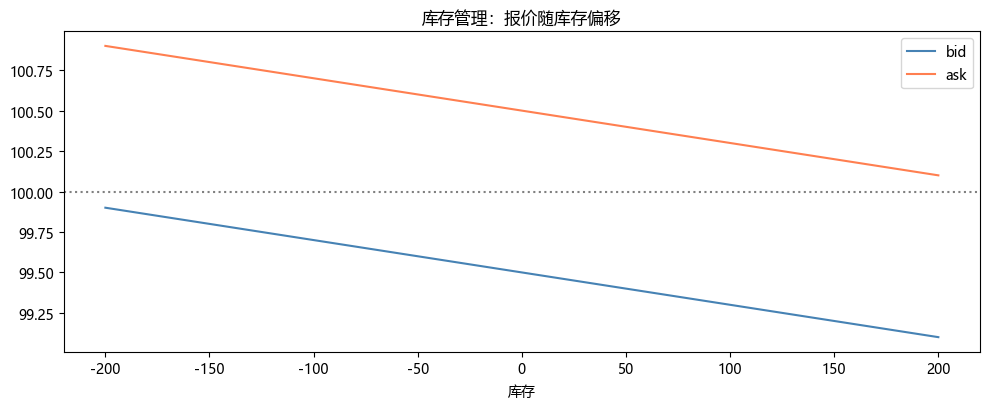

In [2]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
invs = np.linspace(-200, 200, 20)
bids, asks = [], []
for inv in invs:
    b, a = mm.make_quote(100, 0.5, inv, 0.002); bids.append(b); asks.append(a)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(invs, bids, label='bid', color='steelblue')
ax.plot(invs, asks, label='ask', color='coral')
ax.axhline(100, color='gray', ls=':'); ax.set_xlabel('库存')
ax.set_title('库存管理：报价随库存偏移'); ax.legend()
plt.tight_layout(); plt.show()

## 四、面试要点

- **做市商如何赚钱？** 低买高卖赚双边价差，靠大量成交与库存控制。
- **逆向选择风险？** 知情交易者利用信息优势成交，做市商需用价差与库存偏移补偿。
- **库存为何要偏移报价？** 库存偏多时下调报价促卖出，防止单边敞口的价格风险。
- **高频的关键能力？** 低延迟、队列优先级、共址托管、稳健的风控与撤单机制。

## 五、练习

1. 实现 Avellaneda-Stoikov 做市模型。
2. 模拟知情/不知情交易者混合下的做市损益。
3. 计算有效价差与价格冲击。
4. 讨论撤单率监管与高频合规。